In [1]:
!pip install -q ultralytics imagehash
!git clone -q https://github.com/Shenggan/BCCD_Dataset.git
!ls BCCD_Dataset/BCCD
!ls BCCD_Dataset/BCCD/ImageSets/Main | head

Annotations  ImageSets	JPEGImages
test.txt
train.txt
trainval.txt
val.txt


In [2]:
import xml.etree.ElementTree as ET, os, shutil, collections

CLASSES = ["RBC", "WBC", "Platelets"]
ROOT = "BCCD_Dataset/BCCD"

def convert(split):
    ids = open(f"{ROOT}/ImageSets/Main/{split}.txt").read().split()
    os.makedirs(f"bccd/images/{split}", exist_ok=True)
    os.makedirs(f"bccd/labels/{split}", exist_ok=True)
    counts = collections.Counter()
    for i in ids:
        r = ET.parse(f"{ROOT}/Annotations/{i}.xml").getroot()
        W, H = float(r.find("size/width").text), float(r.find("size/height").text)
        lines = []
        for o in r.findall("object"):
            name = o.find("name").text.strip()
            if name not in CLASSES:
                continue
            b = o.find("bndbox")
            x1, y1, x2, y2 = [float(b.find(k).text) for k in ["xmin", "ymin", "xmax", "ymax"]]
            x1, x2 = max(0, min(x1, x2)), min(W, max(x1, x2))   # fix swapped or out-of-bounds boxes
            y1, y2 = max(0, min(y1, y2)), min(H, max(y1, y2))
            if x2 - x1 < 1 or y2 - y1 < 1:
                continue
            lines.append(f"{CLASSES.index(name)} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} "
                         f"{(x2-x1)/W:.6f} {(y2-y1)/H:.6f}")
            counts[name] += 1
        shutil.copy(f"{ROOT}/JPEGImages/{i}.jpg", f"bccd/images/{split}/{i}.jpg")
        open(f"bccd/labels/{split}/{i}.txt", "w").write("\n".join(lines))
    return len(ids), counts

for split in ["train", "val", "test"]:
    n, c = convert(split)
    print(f"{split:5s}: {n} images, cells: {dict(c)}")

open("bccd.yaml", "w").write(f"""path: {os.path.abspath('bccd')}
train: images/train
val: images/val
test: images/test
names: {dict(enumerate(CLASSES))}
""")
print(open("bccd.yaml").read())

train: 205 images, cells: {'WBC': 214, 'RBC': 2381, 'Platelets': 209}
val  : 87 images, cells: {'WBC': 87, 'RBC': 967, 'Platelets': 83}
test : 72 images, cells: {'WBC': 71, 'RBC': 805, 'Platelets': 69}
path: /content/bccd
train: images/train
val: images/val
test: images/test
names: {0: 'RBC', 1: 'WBC', 2: 'Platelets'}



In [3]:
import imagehash
from PIL import Image
import glob

def hashes(split):
    return {os.path.basename(p): imagehash.phash(Image.open(p))
            for p in glob.glob(f"bccd/images/{split}/*.jpg")}

h_train, h_test = hashes("train"), hashes("test")
pairs = [(t, s, h_test[t] - h_train[s]) for t in h_test for s in h_train if h_test[t] - h_train[s] <= 6]
near = sorted({t for t, _, _ in pairs})
print(f"Test images with a near-duplicate in training (hash distance <= 6): {len(near)} of {len(h_test)}")
for t, s, d in sorted(pairs, key=lambda x: x[2])[:10]:
    print(f"  {t} ~ {s} (distance {d})")

Test images with a near-duplicate in training (hash distance <= 6): 0 of 72


In [4]:
from ultralytics import YOLO

common = dict(data="bccd.yaml", epochs=60, imgsz=640, batch=16, seed=0, deterministic=True,
              plots=False, verbose=False, exist_ok=True)

m_base = YOLO("yolov8n.pt")
m_base.train(name="no_color_aug", hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, **common)

m_aug = YOLO("yolov8n.pt")
m_aug.train(name="strong_color_aug", hsv_h=0.05, hsv_s=0.9, hsv_v=0.6, **common)

WEIGHTS = {"No color augmentation": "runs/detect/no_color_aug/weights/best.pt",
           "Strong color augmentation": "runs/detect/strong_color_aug/weights/best.pt"}

def evaluate(weights, data="bccd.yaml"):
    r = YOLO(weights).val(data=data, split="test", imgsz=640, verbose=False, plots=False)
    per_class = {CLASSES[i]: ap for i, ap in zip(r.box.ap_class_index, r.box.ap50)}
    return r.box.map50, per_class

for name, w in WEIGHTS.items():
    overall, pc = evaluate(w)
    print(f"{name:26s}: mAP50 = {overall:.3f} | " + ", ".join(f"{k} {v:.3f}" for k, v in pc.items()))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=bccd.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0

In [5]:
import numpy as np, cv2, glob, shutil

def shift_image(img, kind):
    if kind == "color_cast":       # warmer white balance (like a different camera)
        return np.clip(img * np.array([0.8, 1.0, 1.25]), 0, 255).astype(np.uint8)   # B, G, R
    if kind == "darker":           # weaker illumination
        return np.clip(img * 0.6, 0, 255).astype(np.uint8)
    if kind == "blur":             # slightly out of focus
        return cv2.GaussianBlur(img, (0, 0), 2.0)
    if kind == "jpeg_q15":         # heavy compression (e.g., messaging apps)
        return cv2.imdecode(cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 15])[1], 1)
    if kind == "low_res":          # lower-resolution camera
        h, w = img.shape[:2]
        small = cv2.resize(img, (int(w * 0.4), int(h * 0.4)), interpolation=cv2.INTER_AREA)
        return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    return img

SHIFTS = ["original", "color_cast", "darker", "blur", "jpeg_q15", "low_res"]
for kind in SHIFTS[1:]:
    base = f"bccd_shift/{kind}"
    os.makedirs(f"{base}/images/test", exist_ok=True)
    shutil.copytree("bccd/labels/test", f"{base}/labels/test", dirs_exist_ok=True)
    for p in glob.glob("bccd/images/test/*.jpg"):
        cv2.imwrite(f"{base}/images/test/{os.path.basename(p)}", shift_image(cv2.imread(p), kind))
    open(f"{base}.yaml", "w").write(f"path: {os.path.abspath(base)}\ntrain: images/test\nval: images/test\n"
                                    f"test: images/test\nnames: {dict(enumerate(CLASSES))}\n")

rows = []
for kind in SHIFTS:
    data = "bccd.yaml" if kind == "original" else f"bccd_shift/{kind}.yaml"
    for name, w in WEIGHTS.items():
        overall, pc = evaluate(w, data)
        rows.append(dict(shift=kind, model=name, mAP50=overall, **pc))
res = pd.DataFrame(rows) if "pd" in dir() else __import__("pandas").DataFrame(rows)
print(res.round(3).to_string(index=False))

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1183.7±362.1 MB/s, size: 20.2 KB)
val: Scanning /content/bccd/labels/test.cache... 72 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 72/72 20.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.3it/s 0.9s
                   all         72        945      0.834        0.9      0.918      0.618
Speed: 1.0ms preprocess, 4.3ms inference, 0.0ms loss, 2.3ms postprocess per image
Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 687.6±250.6 MB/s, size: 20.1 KB)
val: Scanning /content/bccd/labels/test.cache... 72 images, 0 backgrounds, 0 corrupt

In [6]:
def gray_world(img):
    """Scale each color channel so the image's average color is neutral gray."""
    means = img.reshape(-1, 3).mean(0)
    return np.clip(img * (means.mean() / means), 0, 255).astype(np.uint8)

# 1. Normalized copy of the original dataset (train, val, test)
for split in ["train", "val", "test"]:
    os.makedirs(f"bccd_gw/images/{split}", exist_ok=True)
    shutil.copytree(f"bccd/labels/{split}", f"bccd_gw/labels/{split}", dirs_exist_ok=True)
    for p in glob.glob(f"bccd/images/{split}/*.jpg"):
        cv2.imwrite(f"bccd_gw/images/{split}/{os.path.basename(p)}", gray_world(cv2.imread(p)))
open("bccd_gw.yaml", "w").write(f"path: {os.path.abspath('bccd_gw')}\ntrain: images/train\nval: images/val\n"
                                f"test: images/test\nnames: {dict(enumerate(CLASSES))}\n")

# 2. Normalized copies of each shifted test set (shift first, then normalize, as in real use)
for kind in SHIFTS[1:]:
    base = f"bccd_shift_gw/{kind}"
    os.makedirs(f"{base}/images/test", exist_ok=True)
    shutil.copytree("bccd/labels/test", f"{base}/labels/test", dirs_exist_ok=True)
    for p in glob.glob("bccd/images/test/*.jpg"):
        cv2.imwrite(f"{base}/images/test/{os.path.basename(p)}", gray_world(shift_image(cv2.imread(p), kind)))
    open(f"{base}.yaml", "w").write(f"path: {os.path.abspath(base)}\ntrain: images/test\nval: images/test\n"
                                    f"test: images/test\nnames: {dict(enumerate(CLASSES))}\n")

# 3. Train on normalized images (no color augmentation, to isolate the effect of normalization)
m_gw = YOLO("yolov8n.pt")
m_gw.train(data="bccd_gw.yaml", name="gray_world", hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
           **{k: v for k, v in common.items() if k != "data"})
w_gw = "runs/detect/gray_world/weights/best.pt"

# 4. Evaluate on every normalized test set
for kind in SHIFTS:
    data = "bccd_gw.yaml" if kind == "original" else f"bccd_shift_gw/{kind}.yaml"
    overall, pc = evaluate(w_gw, data)
    rows.append(dict(shift=kind, model="Gray-world normalization", mAP50=overall, **pc))

res = pd.DataFrame(rows)
print(res.sort_values(["shift", "model"]).round(3).to_string(index=False))

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=bccd_gw.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=gray_world, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overla

NameError: name 'pd' is not defined

In [7]:
import pandas as pd
res = pd.DataFrame(rows)
print(res.sort_values(["shift", "model"]).round(3).to_string(index=False))

     shift                     model  mAP50   RBC   WBC  Platelets
      blur  Gray-world normalization  0.927 0.870 0.983      0.927
      blur     No color augmentation  0.915 0.859 0.988      0.899
      blur Strong color augmentation  0.911 0.864 0.975      0.893
color_cast  Gray-world normalization  0.926 0.875 0.985      0.918
color_cast     No color augmentation  0.634 0.814 0.977      0.111
color_cast Strong color augmentation  0.700 0.836 0.949      0.314
    darker  Gray-world normalization  0.868 0.729 0.965      0.911
    darker     No color augmentation  0.794 0.676 0.955      0.751
    darker Strong color augmentation  0.913 0.872 0.973      0.895
  jpeg_q15  Gray-world normalization  0.893 0.785 0.981      0.912
  jpeg_q15     No color augmentation  0.855 0.735 0.980      0.851
  jpeg_q15 Strong color augmentation  0.895 0.805 0.970      0.909
   low_res  Gray-world normalization  0.927 0.873 0.981      0.927
   low_res     No color augmentation  0.918 0.863 0.989      0

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=bccd_gw.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.6, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=gray_world_brightness, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

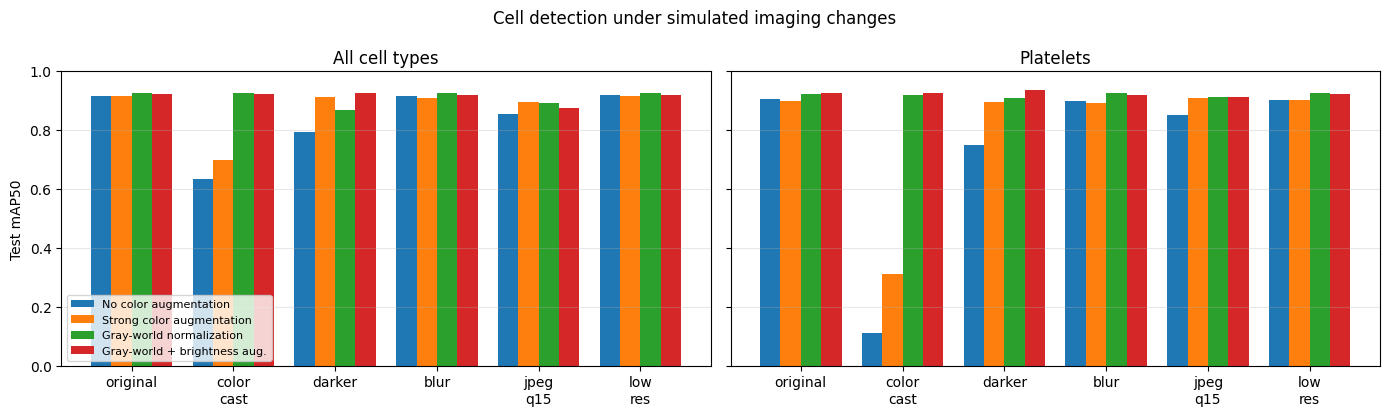

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
import matplotlib.pyplot as plt

# 1. Train on normalized images with brightness augmentation only (no hue/saturation changes)
m_combo = YOLO("yolov8n.pt")
m_combo.train(data="bccd_gw.yaml", name="gray_world_brightness", hsv_h=0.0, hsv_s=0.0, hsv_v=0.6,
              **{k: v for k, v in common.items() if k != "data"})
w_combo = "runs/detect/gray_world_brightness/weights/best.pt"

for kind in SHIFTS:
    data = "bccd_gw.yaml" if kind == "original" else f"bccd_shift_gw/{kind}.yaml"
    overall, pc = evaluate(w_combo, data)
    rows.append(dict(shift=kind, model="Gray-world + brightness aug.", mAP50=overall, **pc))

res = pd.DataFrame(rows)
print(res.sort_values(["shift", "model"]).round(3).to_string(index=False))

# 2. Figure: overall accuracy and platelet accuracy under each imaging change
MODELS = ["No color augmentation", "Strong color augmentation",
          "Gray-world normalization", "Gray-world + brightness aug."]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
x = np.arange(len(SHIFTS)); w = 0.2
for ax, col, title in [(axes[0], "mAP50", "All cell types"), (axes[1], "Platelets", "Platelets")]:
    for i, m in enumerate(MODELS):
        d = res[res.model == m].set_index("shift").loc[SHIFTS]
        ax.bar(x + (i - 1.5) * w, d[col], w, label=m)
    ax.set_xticks(x); ax.set_xticklabels([s.replace("_", "\n") for s in SHIFTS])
    ax.set_title(title); ax.set_ylim(0, 1); ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Test mAP50"); axes[0].legend(fontsize=8, loc="lower left")
plt.suptitle("Cell detection under simulated imaging changes")
plt.tight_layout(); plt.savefig("robustness.png", dpi=200, bbox_inches="tight"); plt.show()

from google.colab import files
files.download("robustness.png")

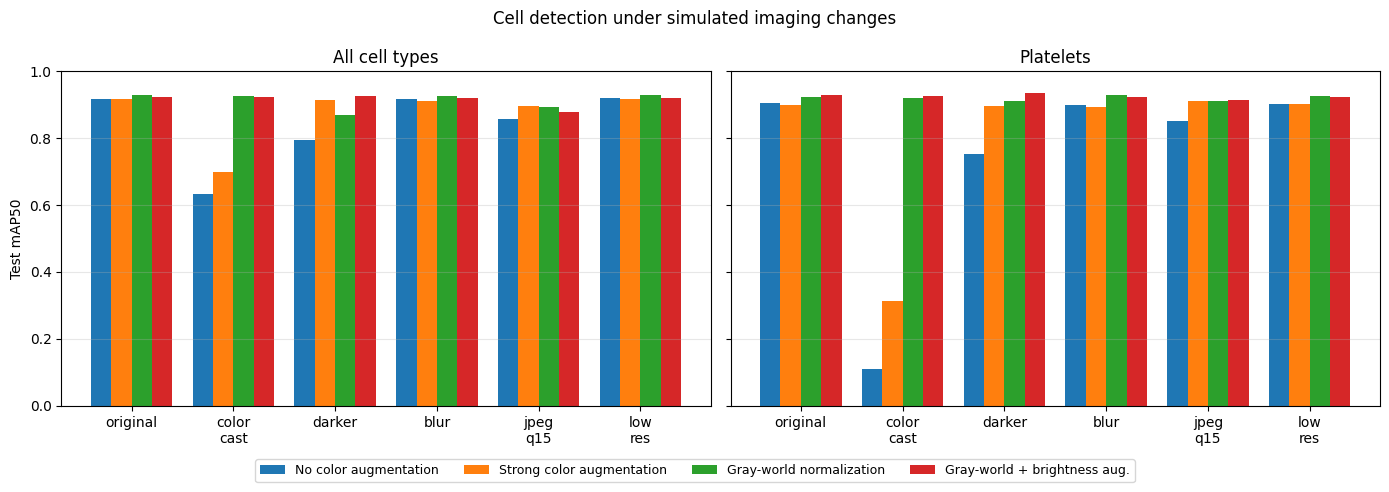

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
x = np.arange(len(SHIFTS)); w = 0.2
for ax, col, title in [(axes[0], "mAP50", "All cell types"), (axes[1], "Platelets", "Platelets")]:
    for i, m in enumerate(MODELS):
        d = res[res.model == m].set_index("shift").loc[SHIFTS]
        ax.bar(x + (i - 1.5) * w, d[col], w, label=m)
    ax.set_xticks(x); ax.set_xticklabels([s.replace("_", "\n") for s in SHIFTS])
    ax.set_title(title); ax.set_ylim(0, 1); ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Test mAP50")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.06), fontsize=9)
plt.suptitle("Cell detection under simulated imaging changes")
plt.tight_layout(); plt.savefig("robustness.png", dpi=200, bbox_inches="tight"); plt.show()
files.download("robustness.png")